# 4.1 Clustering

k-means (incl. choosing K), hierarchical clustering with a dendrogram, and
DBSCAN -- on the same customer table, now used *unsupervised* (the
`churned`/`monthly_spend` labels are set aside and only used afterwards, to
sanity-check what the clusters found).

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
X_scaled = StandardScaler().fit_transform(X)  # clustering is distance-based, same scaling reason as k-NN in 3.3

# only for the 2-D scatterplots below -- clustering itself uses all 7 features
X_2d = PCA(n_components=2, random_state=0).fit_transform(X_scaled)

## K-means: choosing K

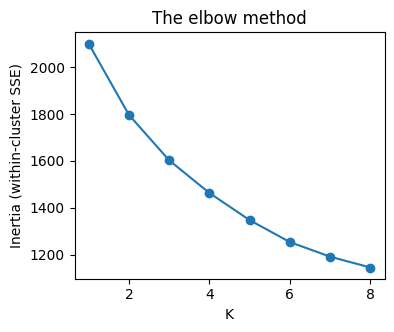

In [3]:
from sklearn.cluster import KMeans

inertias = []
Ks = range(1, 9)
for k in Ks:
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled).inertia_)

fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(Ks, inertias, marker="o")
ax.set_xlabel("K"); ax.set_ylabel("Inertia (within-cluster SSE)"); ax.set_title("The elbow method")
plt.show()

Look for the "elbow" -- the K after which adding another cluster only
shaves a little more off the within-cluster SSE. Not always crisp (as
here), which is itself the point of the "considerations" slide: K-means
needs you to *choose* K, it won't tell you the right answer on its own.

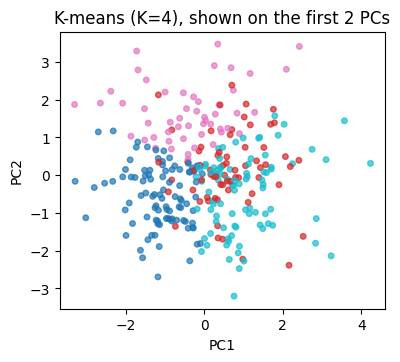

,age,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
cluster_kmeans,,,,,,,,,
0,31.67,29.13,51.53,24.62,2.91,3.35,7.56,39.38,0.30
1,44.63,32.41,74.50,22.38,3.23,13.94,7.40,37.74,0.36
2,45.19,70.58,72.98,27.22,1.94,3.37,8.07,45.82,0.04
3,47.62,24.22,78.46,23.43,4.42,2.33,6.76,40.80,0.55


In [4]:
k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled)
df["cluster_kmeans"] = kmeans.labels_

fig, ax = plt.subplots(figsize=(4.2, 3.6))
sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans.labels_, cmap="tab10", s=16, alpha=0.7)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"K-means (K={k}), shown on the first 2 PCs")
plt.show()

df.groupby("cluster_kmeans")[features + ["monthly_spend", "churned"]].mean().round(2)

Even though clustering never saw `churned` or `monthly_spend`, the
per-cluster averages above often line up with them anyway (e.g. one
cluster with low satisfaction/high support calls tends to have a higher
churn rate) -- clusters found on behavioural features alone can still
correlate with the outcomes we cared about in Sections 2-3.

## Hierarchical clustering and the dendrogram

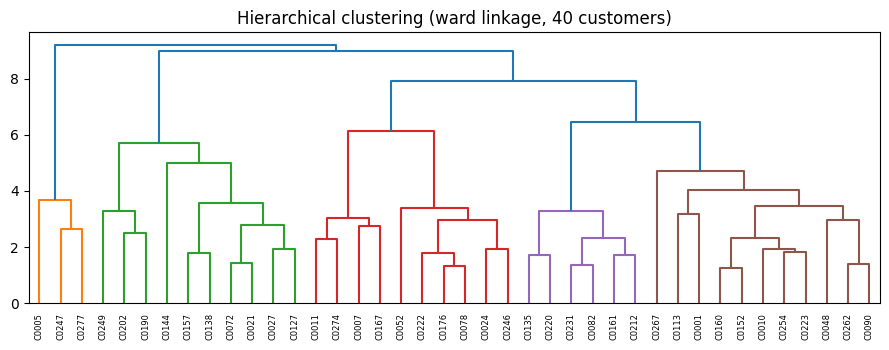

In [5]:
from scipy.cluster.hierarchy import dendrogram, linkage

# a small subsample so the dendrogram stays readable
sample_idx = np.random.default_rng(0).choice(len(X_scaled), size=40, replace=False)
Z = linkage(X_scaled[sample_idx], method="ward")

fig, ax = plt.subplots(figsize=(9, 3.6))
dendrogram(Z, ax=ax, labels=df["customer_id"].values[sample_idx], leaf_rotation=90, leaf_font_size=6)
ax.set_title("Hierarchical clustering (ward linkage, 40 customers)")
plt.tight_layout(); plt.show()

Read the dendrogram bottom-up: each join is where two clusters (or points)
merge, and the join's height is how (dis)similar they were -- cutting the
tree at a given height gives you a clustering with that many groups, no
need to pre-commit to K the way k-means does.

## DBSCAN: density-based clustering

DBSCAN found 3 clusters and flagged 257 points as noise


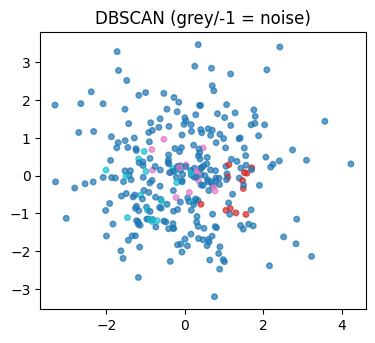

In [6]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=1.2, min_samples=5).fit(X_scaled)
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = (db.labels_ == -1).sum()
print(f"DBSCAN found {n_clusters} clusters and flagged {n_noise} points as noise")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=db.labels_, cmap="tab10", s=16, alpha=0.7)
ax.set_title("DBSCAN (grey/-1 = noise)")
plt.show()

**Takeaway**: k-means needs K chosen up front and assumes roughly
round/similarly-sized clusters; hierarchical clustering trades that for a
full dendrogram you can cut at any level; DBSCAN needs no K at all and can
find irregularly-shaped clusters, but it can label a chunk of the data as
"noise" rather than forcing it into a group -- three different answers to
"how many groups, and how firm are the boundaries?".